In [1]:
import matplotlib.pyplot as plt
from matplotlib.animation import PillowWriter
import matplotlib.animation as animation
plt.rcParams["animation.html"] = "jshtml"
import warnings
import zarr
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats

In [2]:
zarrPath = "/home/exouser/labfetch/data/cali1mounthaug25.zarr"
store = zarr.open_group(zarrPath, mode='r')
available_fires = list(store.group_keys())
ds = xr.open_zarr(zarrPath, group=available_fires[0], consolidated=False)
ds.load() 

<xarray.Dataset> Size: 4GB
Dimensions:              (time: 743, y: 456, x: 415)
Coordinates:
  * time                 (time) datetime64[ns] 6kB 2025-08-01T01:00:00 ... 20...
    lat                  (y, x) float64 2MB 29.89 29.9 29.9 ... 44.39 44.4 44.4
    lon                  (y, x) float64 2MB 235.9 235.9 235.9 ... 245.9 245.9
    valid_time           datetime64[ns] 8B 2025-08-31T23:00:00
    surface              float64 8B 0.0
    step                 timedelta64[ns] 8B 00:00:00
    heightAboveGround    float64 8B 10.0
    gribfile_projection  float64 8B nan
Dimensions without coordinates: y, x
Data variables:
    u10                  (time, y, x) float32 562MB -1.731 -1.669 ... -2.426
    rave_frp             (time, y, x) float32 562MB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    t2m                  (time, y, x) float32 562MB 292.0 292.0 ... 301.0 300.6
    elevation            (time, y, x) float32 562MB 0.01339 0.01339 ... 1.79e+03
    sp                   (time, y, x) float32 562MB 1.02e+05 ... 8.259e+04
    v10                  (time, y, x) float32 562MB -7.46 -7.46 ... 0.4993 1.687
    d2m                  (time, y, x) float32 562MB 290.6 290.6 ... 273.2 273.3
Attributes: (12/15)
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    ...                      ...
    remote_grib:             https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr....
    local_grib:              data/raw_hrrr/hrrr/20250831/subset_35efe9b8__hrr...
    search:                  :TMP:2 m|:DPT:2 m|:UGRD:10 m|:VGRD:10 m|:PBLH:|:...
    TEMPORAL_CLIP_STATUS:    FULLY_CONTAINED
    END_DATE_TYPE:           Ongoing Capped
    ONGOING_STATUS:          ARTIFICIALLY_CAPPED

In [5]:
times = ds.time.values

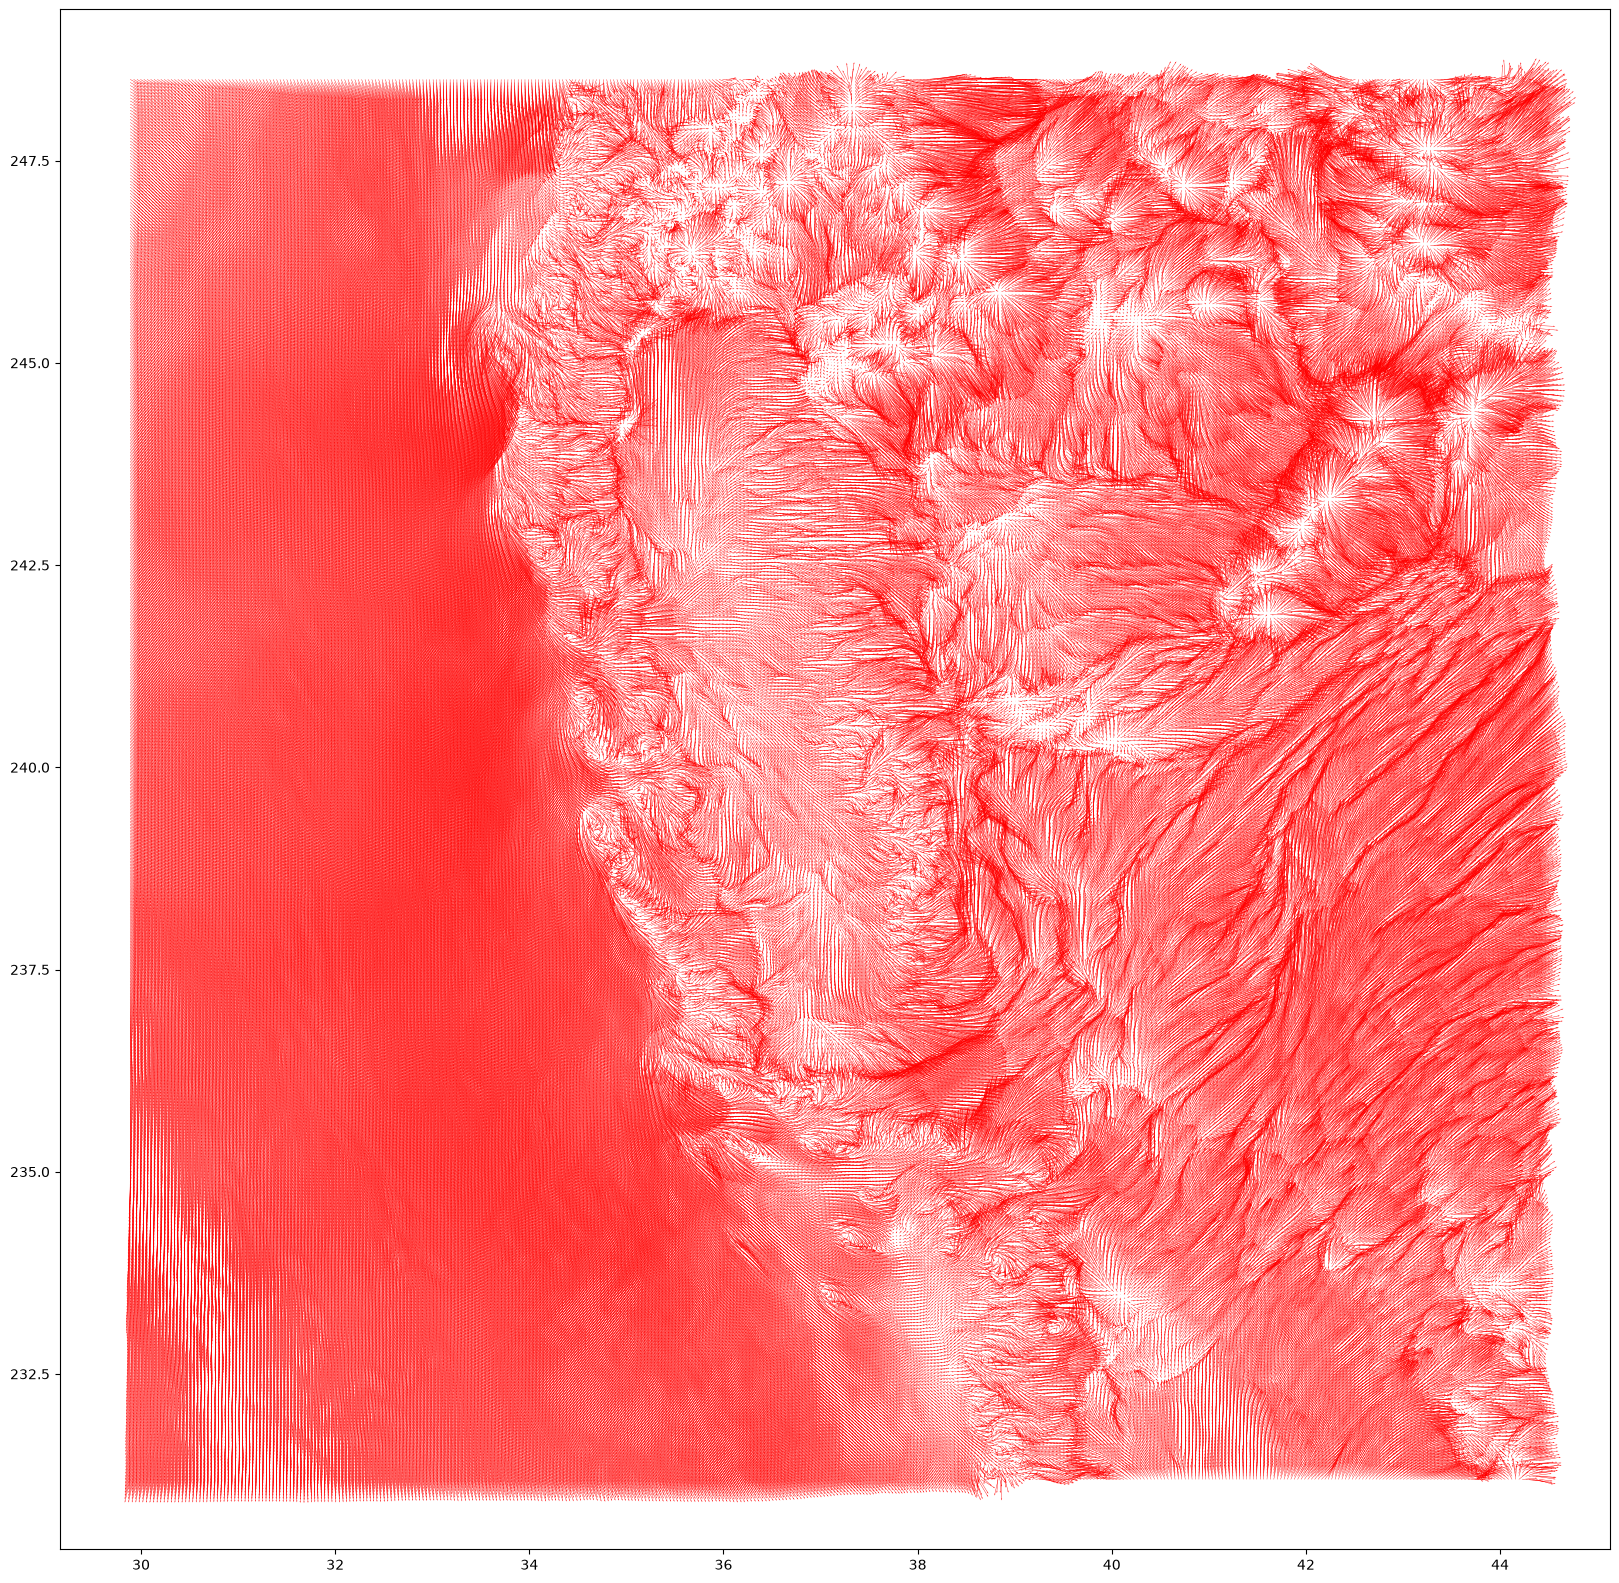

In [10]:
#times = ds.valid_time.values

weather_current = ds.sel(indexers={'time':"2025-08-01T01:00:00"},method='nearest')

# X
lonMax = weather_current.lon.values.max()
lonMin = weather_current.lon.values.min()
# Y
latMin = weather_current.lat.values.min()
latMax = weather_current.lat.values.max()

U = weather_current.u10.values
V = weather_current.v10.values
frp = weather_current.rave_frp.values
x = np.linspace(lonMin, lonMax, 456)
y = np.linspace(latMin, latMax, 415)
X, Y = np.meshgrid(y, x)
scatter_x = X.ravel()
scatter_y = Y.ravel()
staion_long = []
station_lat = []


fig, ax = plt.subplots(figsize=(20, 20))
fires = ax.scatter(scatter_x, scatter_y, c=frp, cmap="gray", s=10,zorder=0)
wind = ax.quiver(X, Y, U, V,color="red", scale=500, width=0.00025,zorder=1)
 

def update(frame):
    
    current_time = times[frame]
    weather_current = ds.sel(indexers={'time':current_time},method='nearest')

    U = weather_current.u10.values
    V = weather_current.v10.values
    frp = weather_current.rave_frp.values
    
    # update the scatter plot:
    fires.set_offsets(frp)
    # update the line plot:
    wind.set_UVC(U,V)
    
    return (fires, wind)


ani = animation.FuncAnimation(fig=fig, func=update, frames=168) #, interval=30
#plt.show()
writer = PillowWriter(fps=30)
ani.save("animation2.gif", writer=writer)


In [ ]:
weather_current = ds.sel(indexers={'time':"2025-08-01T01:00:00"},method='nearest')

In [ ]:
# X
lonMax = weather_current.lon.values.max()
lonMin = weather_current.lon.values.min()
# Y
latMin = weather_current.lat.values.min()
latMax = weather_current.lat.values.max()

In [ ]:
# 1. Get the base colormap
cmap = plt.colormaps['viridis'].resampled(256)
# 2. Modify the very first color (under the assumption 0 is your minimum value)
new_colors = cmap(np.linspace(0, 1, 256))
new_colors[0, 3] = 0.0  # Set alpha of the lowest value to 0 (transparent)

# 3. Create a new colormap from the modified matrix
from matplotlib.colors import ListedColormap
custom_cmap = ListedColormap(new_colors)


In [ ]:


weather_current = ds.sel(indexers={'time':"2025-08-01T01:00:00"},method='nearest')

U = weather_current.u10.values
V = weather_current.v10.values
frp = weather_current.rave_frp.values
x = np.linspace(lonMin, lonMax, 456)
y = np.linspace(latMin, latMax, 415)
X, Y = np.meshgrid(y, x)
scatter_x = X.ravel()
scatter_y = Y.ravel()
staion_long = []
station_lat = []

fig, ax = plt.subplots(figsize=(20, 20))
ax.scatter(scatter_x, scatter_y, c=frp, cmap="gray", s=10,zorder=0)
ax.quiver(X, Y, U, V,color="red", scale=500, width=0.00025,zorder=1)
 

plt.xlabel("U Component")
plt.ylabel("V Component")
plt.title("Wind")
plt.show()
#plt.quiver(X, Y, U, V, scale=500, width=0.00007)
#plt.grid()

In [ ]:
times = ds.valid_time.values
ds.valid_time.values

In [ ]:
times = ds.valid_time.values


fig, ax = plt.subplots(figsize=(20, 20))
fires = ax.scatter(scatter_x, scatter_y, c=frp, cmap="gray", s=10,zorder=0)
wind = ax.quiver(X, Y, U, V,color="red", scale=500, width=0.00025,zorder=1)
 

def update(frame):
    
    current_time = times[frame]
    weather_current = ds.sel(indexers={'time':current_time},method='nearest')

    U = weather_current.u10.values
    V = weather_current.v10.values
    frp = weather_current.rave_frp.values
    
    # update the scatter plot:
    fires.set_offsets(frp)
    # update the line plot:
    wind.set_UVC(U,V)
    
    return (fires, wind)


ani = animation.FuncAnimation(fig=fig, func=update, frames=30) #, interval=30
writer = PillowWriter(fps=30)
ani.save("animation.gif", writer=writer)


In [ ]:
# plt.figure(figsize=(20,20))
# plt.scatter(scatter_x, scatter_y, c=frp, cmap="gray", s=10,zorder=1) #,zorder=3# zorder ensures points are on top

In [ ]:
# from herbie import Herbie

# # 1. Create a Herbie object for the HRRR surface (sfc) product
# H = Herbie(
#     "2026-08-01 12:00",  # Model initialization time/date
#     model="hrrr",
#     product="sfc",
#     fxx=1,  # Forecast lead time in hours
# )

# # 2. View the inventory to find exact smoke variable strings if needed
# H.inventory("MASSDEN")

# # 3. Download or load smoke mass density (e.g., near-surface smoke) into xarray
# ds = H.xarray("MASSDEN")

# # Or download the specific subset GRIB2 file directly
# H.download("MASSDEN")
# ds = xr.open_dataset("/home/exouser/data/hrrr/20260801/subset_d9e49dd4__hrrr.t12z.wrfsfcf01.grib2", engine="cfgrib")

In [ ]:
# ds.unknown.values

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib import animation

# # Create a coordinate grid
# X, Y = np.mgrid[:2*np.pi:10j, :2*np.pi:5j]
# U = np.cos(X)
# V = np.sin(Y)

# fig, ax = plt.subplots()
# Q = ax.quiver(X, Y, U, V, pivot='mid', color='r', units='inches')

# ax.set_xlim(-1, 7)
# ax.set_ylim(-1, 7)

# # Update function for each frame
# def update_quiver(num, Q, X, Y):
#     U = np.cos(X + num * 0.1)
#     V = np.sin(Y + num * 0.1)
#     Q.set_UVC(U, V)
#     return Q,

# # Run the animation
# anim = animation.FuncAnimation(
#     fig, update_quiver, fargs=(Q, X, Y), interval=50, blit=False
# )

# plt.show()